<a href="https://colab.research.google.com/github/Uwais-ur-Rehman/ML-Project/blob/main/DBSCAN_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
df=pd.read_csv('/content/WineQT.csv')
df.sample(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
173,7.1,0.68,0.07,1.9,0.075,16.0,51.0,0.99685,3.38,0.52,9.5,5,246
111,7.6,0.95,0.03,2.0,0.090,7.0,20.0,0.99590,3.20,0.56,9.6,5,160


In [39]:
df.drop(columns=['Id','quality'],inplace=True)

In [40]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
df_scaled=sc.fit_transform(df)
df=pd.DataFrame(df_scaled,columns=df.columns)
df.sample(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
2,-0.292593,1.273492,-1.161568,-0.171289,0.107253,-0.060071,0.246745,0.140103,-0.325775,-0.045254,-0.593601
1097,-0.750566,0.103932,-0.703785,-0.245072,-0.252560,-0.060071,-0.333092,-0.431556,0.312813,-0.397523,-0.686046


In [41]:
from sklearn.cluster import DBSCAN

In [42]:
db=DBSCAN(eps=1,min_samples=10)

In [43]:
df['Predict']=db.fit_predict(df)

In [44]:
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Predict
0,-0.521580,0.939332,-1.365027,-0.466421,-0.231395,-0.450467,-0.363610,0.555854,1.270695,-0.573658,-0.963382,0
1,-0.292593,1.941813,-1.365027,0.050060,0.234247,0.915920,0.643477,0.036165,-0.708928,0.130881,-0.593601,-1
2,-0.292593,1.273492,-1.161568,-0.171289,0.107253,-0.060071,0.246745,0.140103,-0.325775,-0.045254,-0.593601,-1
3,1.653789,-1.399789,1.483400,-0.466421,-0.252560,0.135127,0.429852,0.659792,-0.964363,-0.456235,-0.593601,-1
4,-0.521580,0.939332,-1.365027,-0.466421,-0.231395,-0.450467,-0.363610,0.555854,1.270695,-0.573658,-0.963382,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1138,-1.151292,-0.118842,-0.703785,-0.171289,-0.231395,1.306316,-0.180503,-0.514707,0.695966,0.541862,0.515741,-1
1139,-0.865059,0.493785,-0.958109,-0.466421,-0.400719,1.208717,-0.241539,-0.114545,0.695966,0.952843,-0.870937,-1
1140,-1.208538,0.382399,-0.958109,-0.392638,0.064922,1.599113,-0.058432,-0.951246,0.887542,-0.456235,0.053515,-1
1141,-1.380278,0.103932,-0.856379,-0.245072,-0.527712,2.282306,0.155192,-0.836914,1.334554,0.600574,0.700632,-1


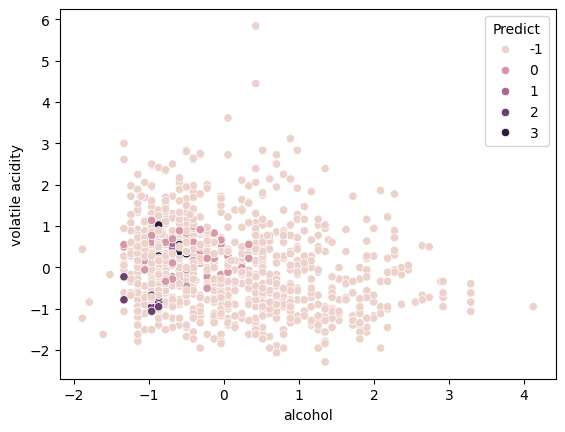

In [45]:
sns.scatterplot(data=df,x='alcohol',y='volatile acidity',hue='Predict')
plt.show()

In [46]:
# Count points in each cluster
print(df['Predict'].value_counts())

Predict
-1    1039
 0      72
 1      11
 2      11
 3      10
Name: count, dtype: int64


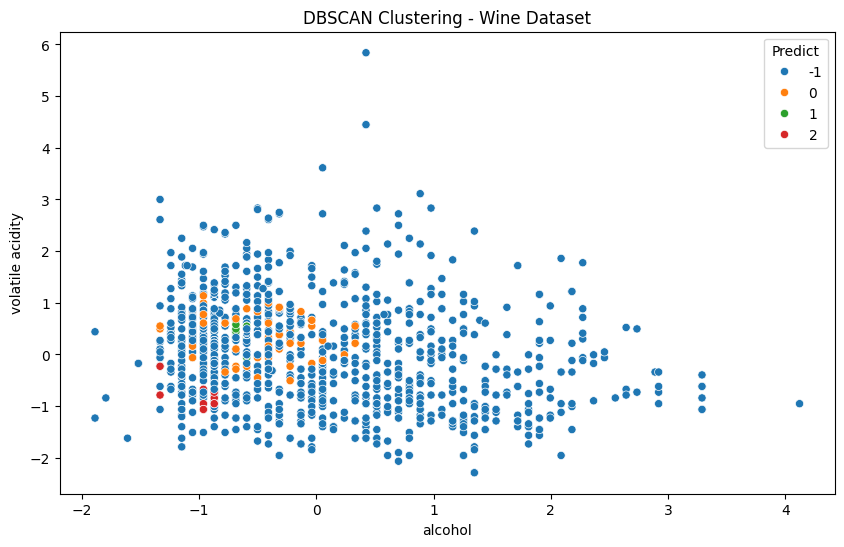

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='alcohol',
    y='volatile acidity',
    hue='Predict',
    palette='tab10',
    hue_order=[-1, 0, 1, 2],
    s=35
)

plt.title('DBSCAN Clustering - Wine Dataset')
plt.show()